In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tools.sm_exceptions import InterpolationWarning

warnings.simplefilter(action="ignore", category=InterpolationWarning)
warnings.simplefilter(action='ignore', category=FutureWarning)

filename = "airline-passengers.csv"
df = pd.read_csv(filename, parse_dates=["Month"], index_col="Month")
df.head()
df.describe()

,Passengers
count,144.000000
mean,280.298611
std,119.966317
min,104.000000
25%,180.000000
50%,265.500000
75%,360.500000
max,622.000000


In [2]:
s = df["Passengers"].asfreq("MS")
print("Frequency:", s.index.freq, "| rows:", len(s), "| missing:", s.isna().sum())
s.describe()

Frequency: <MonthBegin> | rows: 144 | missing: 0


count    144.000000
mean     280.298611
std      119.966317
min      104.000000
25%      180.000000
50%      265.500000
75%      360.500000
max      622.000000
Name: Passengers, dtype: float64

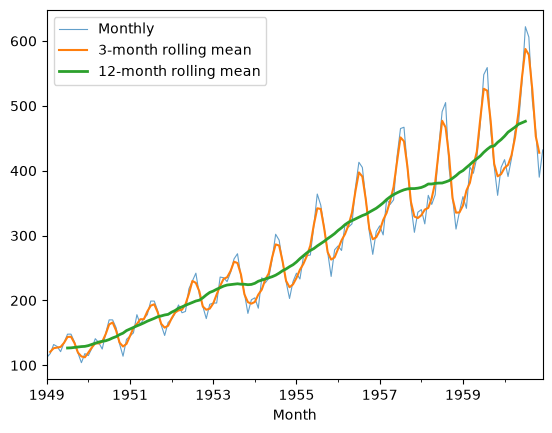

In [3]:
fig, ax = plt.subplots()
s.plot(ax=ax, lw=0.8, alpha=0.7, label="Monthly")
s.rolling(3, center=True).mean().plot(ax=ax, lw=1.5, label="3-month rolling mean")
s.rolling(12, center=True).mean().plot(ax=ax, lw=2, label="12-month rolling mean")
ax.legend()
plt.show()

In [4]:
def stationarity_report(x, name):
    x = x.dropna()
    adf_p = adfuller(x, autolag="AIC")[1]      # H0: non-stationary -> want p < 0.05
    kpss_p = kpss(x, regression="c", nlags="auto")[1]  # H0: stationary -> want p > 0.05
    verdict = "stationary" if (adf_p < 0.05 and kpss_p > 0.05) else "NOT stationary"
    return {"series": name, "n": len(x), "ADF p": round(adf_p, 4),
            "KPSS p": round(kpss_p, 4), "verdict": verdict}

PERIOD = 12   # yearly seasonality in monthly data
WINDOW = 12

In [5]:
results = {}

# Original
results["original"] = s

# 1. Log
log_s = np.log(s)
results["log"] = log_s

# 2. Subtract simple rolling average
results["log - rolling mean"] = log_s - log_s.rolling(WINDOW).mean()

# 3. Subtract exponential rolling average
results["log - EWM mean"] = log_s - log_s.ewm(span=WINDOW, adjust=False).mean()

# 4. Subtract previous value (shift / diff)
results["log diff(1)"] = log_s.diff()                  # same as log_s - log_s.shift(1)
results["log seasonal diff(12)"] = log_s.diff(PERIOD)  # subtract value one year ago

# 5. Seasonal decomposition (keep the residual)
stl = STL(log_s, period=PERIOD, robust=True).fit()
results["log STL residual"] = stl.resid

# 6. Combinations
results["log diff(1) + seasonal diff(12)"] = log_s.diff().diff(PERIOD)
results["log - rolling mean, then diff(1)"] = (log_s - log_s.rolling(WINDOW).mean()).diff()
results["log STL deseasonalised, diff(1)"] = (stl.trend + stl.resid).diff()

In [6]:
report = pd.DataFrame([stationarity_report(v, k) for k, v in results.items()])
report

,series,n,ADF p,KPSS p,verdict
0,original,144,0.9919,0.01,NOT stationary
1,log,144,0.4224,0.01,NOT stationary
2,log - rolling mean,133,0.0222,0.10,stationary
3,log - EWM mean,144,0.0659,0.10,NOT stationary
4,log diff(1),143,0.0711,0.10,NOT stationary
5,log seasonal diff(12),132,0.0724,0.10,NOT stationary
6,log STL residual,144,0.0000,0.10,stationary
7,log diff(1) + seasonal diff(12),131,0.0002,0.10,stationary
8,"log - rolling mean, then diff(1)",132,0.0019,0.10,stationary
9,"log STL deseasonalised, diff(1)",143,0.0000,0.10,stationary


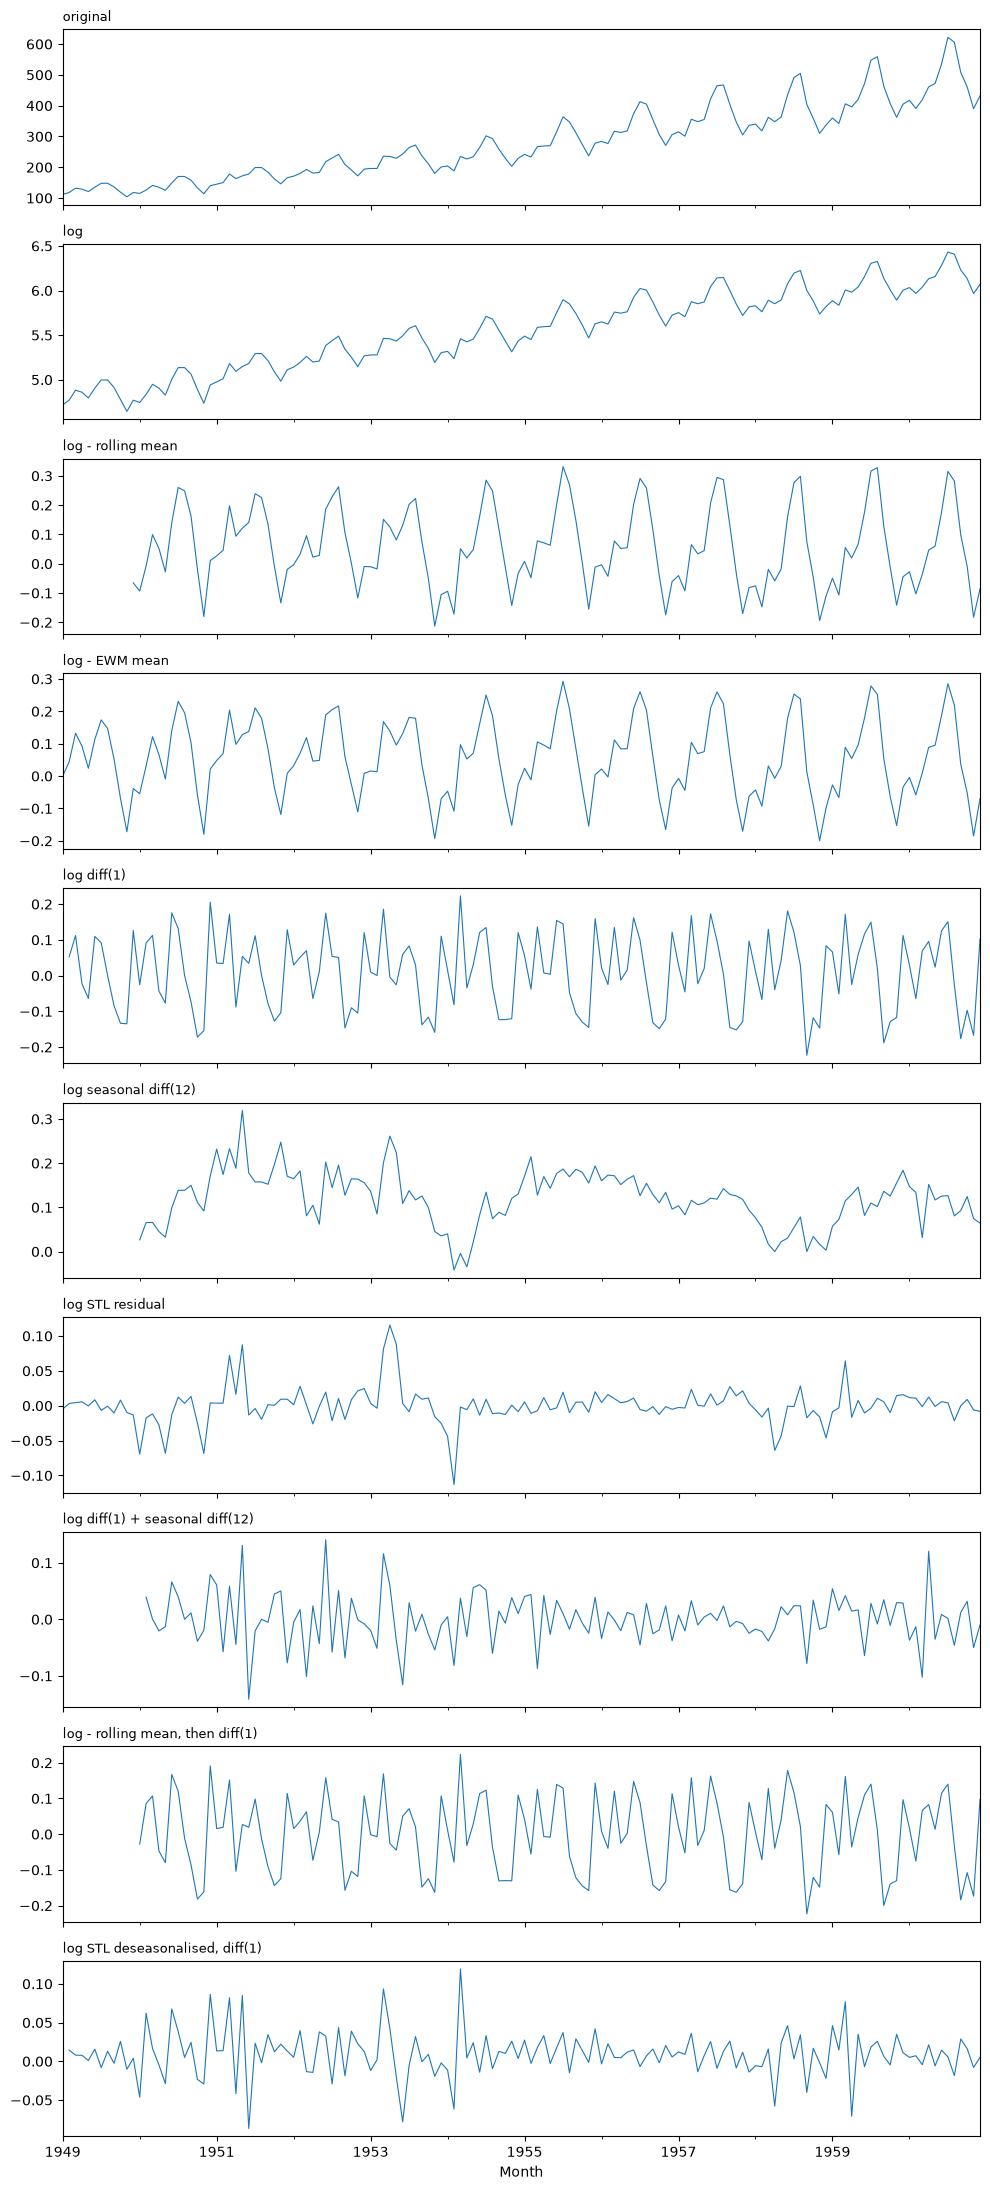

In [7]:
fig, axes = plt.subplots(len(results), 1, figsize=(10, 2.2 * len(results)), sharex=True)
for ax, (name, ser) in zip(axes, results.items()):
    ser.plot(ax=ax, lw=0.8)
    ax.set_title(name, fontsize=9, loc="left")
plt.tight_layout()
plt.show()

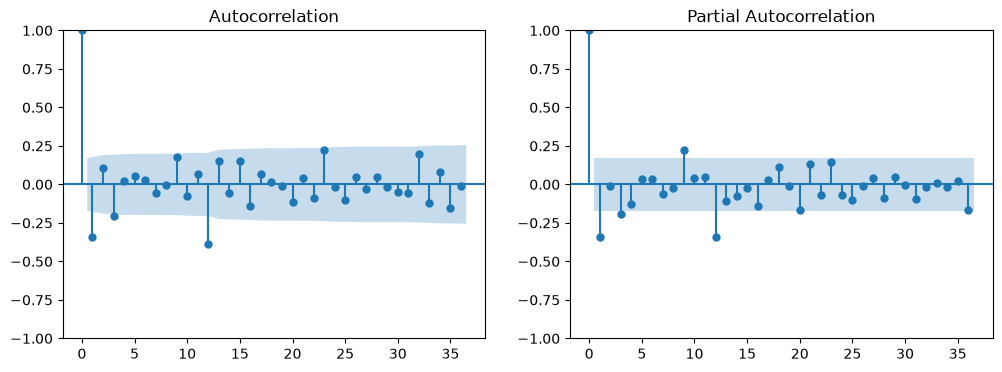

In [8]:
best = results["log diff(1) + seasonal diff(12)"].dropna()   # swap for whichever passes both tests
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(best, lags=36, ax=ax[0])
plot_pacf(best, lags=36, ax=ax[1])
plt.show()

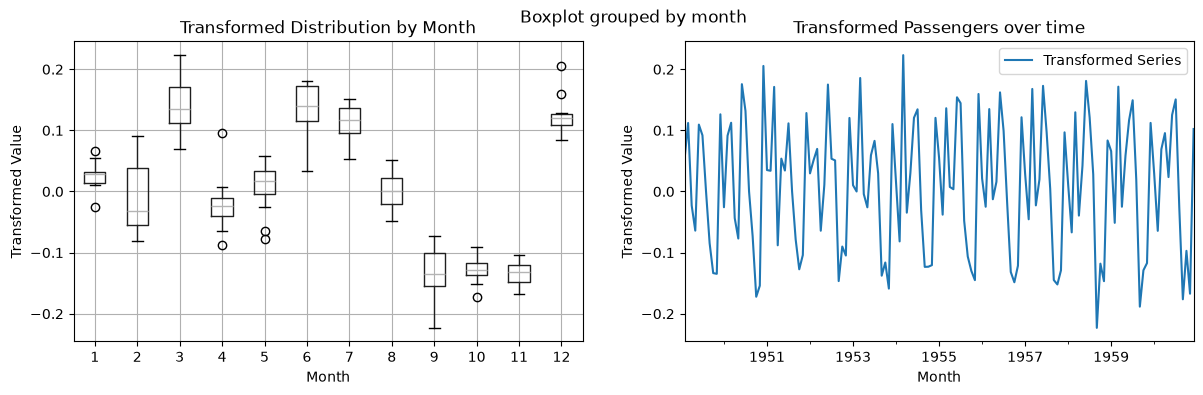

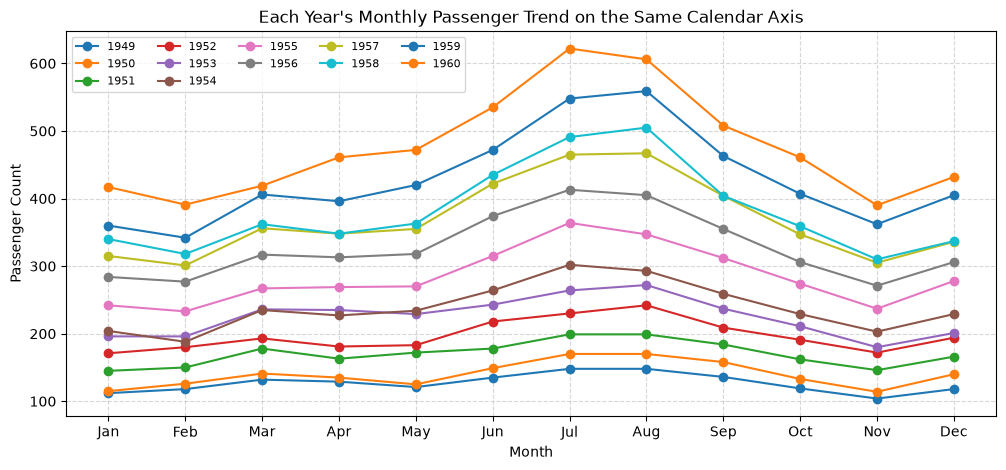

In [13]:
# Apply the best transformation (e.g., Log + Differencing or Log-transformed series)
transformed_s = np.log(s).diff().dropna() # Or use your preferred stationary transformation from the report

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
frame = transformed_s.to_frame("Transformed_Passengers")
frame["month"] = frame.index.month

# Boxplot of the transformed series by month
frame.boxplot(column="Transformed_Passengers", by="month", ax=axes[0])
axes[0].set(title="Transformed Distribution by Month", xlabel="Month", ylabel="Transformed Value")

# Time series plot of the transformed data
axes[1].set(title="Transformed Passengers over time", xlabel="Date", ylabel="Transformed Value")
transformed_s.plot(ax=axes[1], label="Transformed Series")
axes[1].legend()

plt.figure(figsize=(12, 5))

for year, group in s.groupby(s.index.year):
    # Plot monthly values directly by month number (1 to 12)
    plt.plot(group.index.month, group.values, marker='o', label=str(year))

plt.title("Each Year's Monthly Passenger Trend on the Same Calendar Axis")
plt.xlabel("Month")
plt.ylabel("Passenger Count")
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.legend(ncols=5, fontsize=8, loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

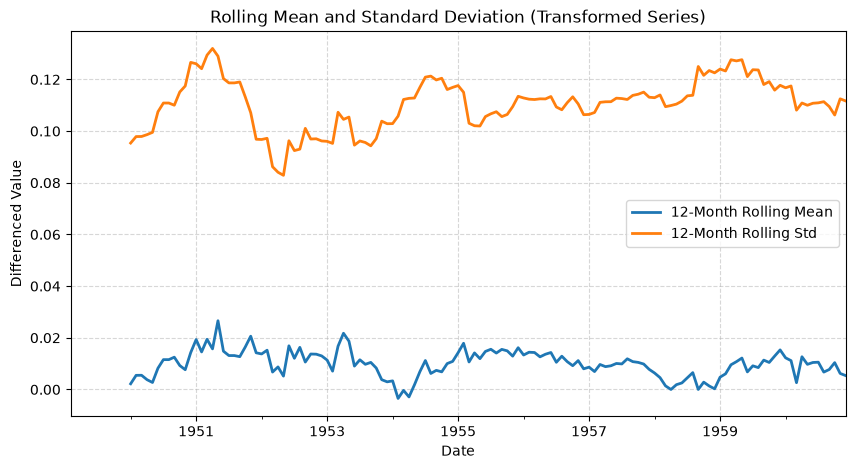

In [17]:
# Create the best transformed and differenced series (Log + 1st diff + Seasonal diff)
transformed_s = np.log(s).diff().dropna()

fig, ax = plt.subplots(figsize=(10, 5))
transformed_s.rolling(12).mean().plot(ax=ax, lw=2, label="12-Month Rolling Mean")
transformed_s.rolling(12).std().plot(ax=ax, lw=2, label="12-Month Rolling Std")
ax.set(title="Rolling Mean and Standard Deviation (Transformed Series)", xlabel="Date", ylabel="Differenced Value")
ax.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

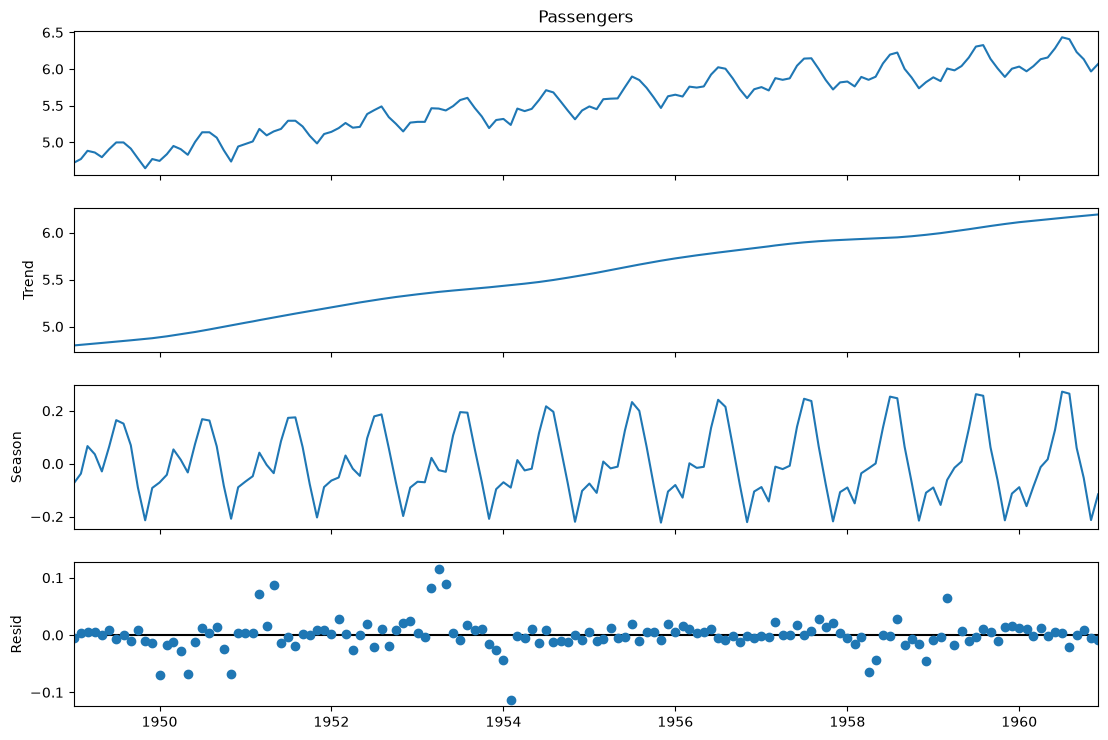

Seasonal share of variance (Log): 8.28%
Trend share of variance (Log): 91.04%
Residual share of variance (Log): 0.36%


In [19]:
# Apply STL decomposition on the log-transformed series to stabilize multiplicative variance
stl_log = STL(np.log(s), period=12, robust=True).fit()
fig = stl_log.plot()
fig.set_size_inches(12, 8)
plt.show()

# Variance share calculations for the log-transformed series
var_total_log = np.log(s).var()
print(f"Seasonal share of variance (Log): {stl_log.seasonal.var() / var_total_log:.2%}")
print(f"Trend share of variance (Log): {stl_log.trend.var() / var_total_log:.2%}")
print(f"Residual share of variance (Log): {stl_log.resid.var() / var_total_log:.2%}")

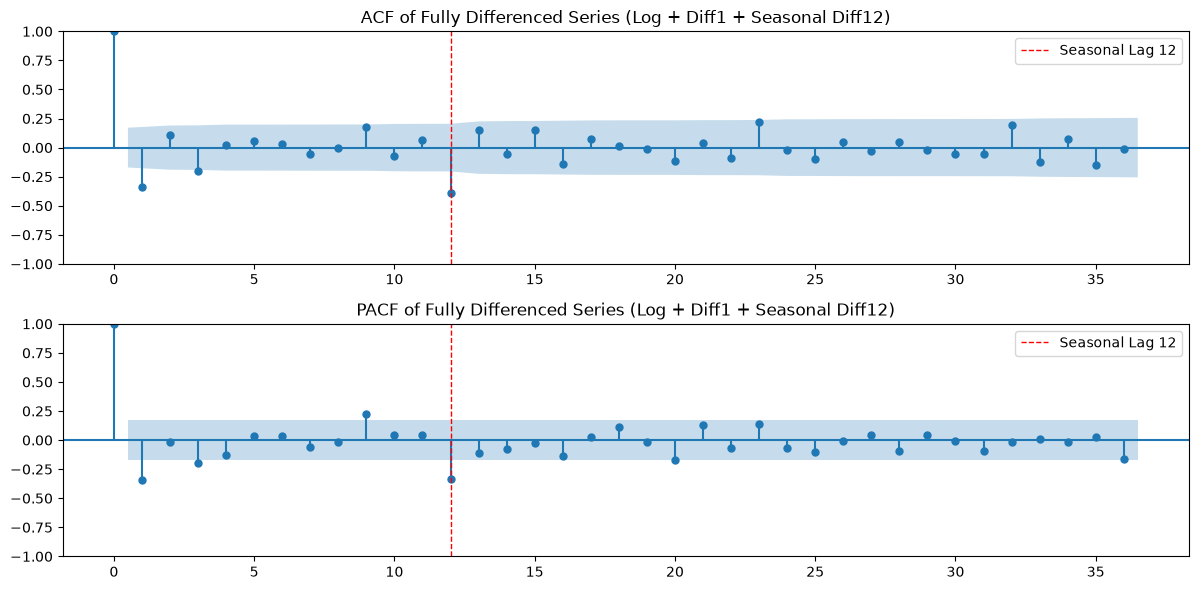

In [22]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Apply full transformation: Log -> First Difference -> Seasonal Difference (lag 12)
diff_s = np.log(s).diff().diff(12).dropna()

fig, axes = plt.subplots(2, 1, figsize=(12, 6))

plot_acf(diff_s, lags=36, ax=axes[0], title="ACF of Fully Differenced Series (Log + Diff1 + Seasonal Diff12)")
axes[0].axvline(x=12, color='r', ls='--', lw=1, label="Seasonal Lag 12")
axes[0].legend()

plot_pacf(diff_s, lags=36, ax=axes[1], title="PACF of Fully Differenced Series (Log + Diff1 + Seasonal Diff12)")
axes[1].axvline(x=12, color='r', ls='--', lw=1, label="Seasonal Lag 12")
axes[1].legend()

plt.tight_layout()
plt.show()

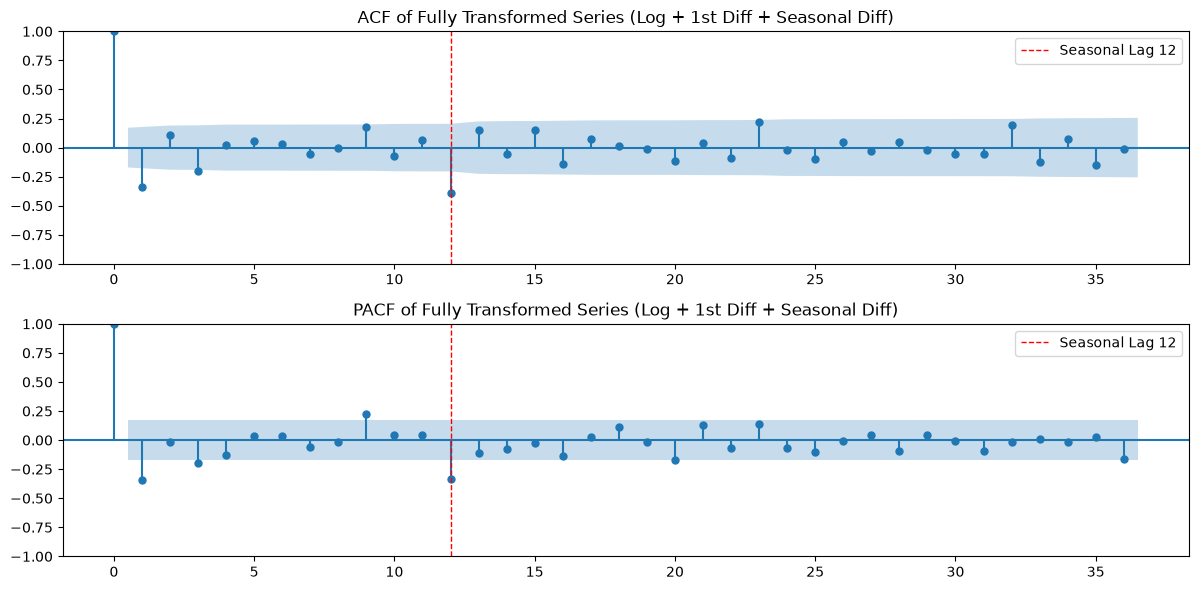

In [24]:
# Apply the full best transformation: Log -> First Difference -> Seasonal Difference (lag 12)
diff_s = np.log(s).diff().diff(12).dropna()

fig, axes = plt.subplots(2, 1, figsize=(12, 6))

plot_acf(diff_s, lags=36, ax=axes[0], title="ACF of Fully Transformed Series (Log + 1st Diff + Seasonal Diff)")
axes[0].axvline(x=12, color='r', ls='--', lw=1, label="Seasonal Lag 12")
axes[0].legend()

plot_pacf(diff_s, lags=36, ax=axes[1], title="PACF of Fully Transformed Series (Log + 1st Diff + Seasonal Diff)")
axes[1].axvline(x=12, color='r', ls='--', lw=1, label="Seasonal Lag 12")
axes[1].legend()

plt.tight_layout()
plt.show()

In [30]:
from statsmodels.tsa.stattools import adfuller

# 1. Ensure log transformation (stabilizes variance)
log_s = np.log(s)

# 2. Apply full differencing (removes trend and seasonal non-stationarity)
# Log -> 1st difference -> Seasonal difference (lag 12)
fully_diffed = log_s.diff().diff(12).dropna()

# 3. Verify stationarity with Augmented Dickey-Fuller test
adf_result = adfuller(fully_diffed)
print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"p-value: {adf_result[1]:.4f}")
print("Stationary!" if adf_result[1] < 0.05 else "Still non-stationary")

# 4. Train/Test Split (1949-1959 train, 1960 test)
m = s.resample("MS").mean()
m_train, m_test = m[:"1959-12-01"], m["1960-01-01":]
log_train = np.log(m_train)

# 5. Fit SARIMAX 
# Note: SARIMax handles the d=1 and D=1, s=12 differencing internally when specified here,
# operating on the log-transformed training data.
model = SARIMAX(log_train, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12))
fit = model.fit(disp=False)

# 6. Forecast and inverse transform back to original passenger scale
steps = len(m_test)
forecast_log = fit.get_forecast(steps=steps)
pred = np.exp(forecast_log.predicted_mean)
pred.index = m_test.index

# 7. Evaluate
def m_eval(pred, name):
    e = m_test - pred
    return {"model": name, "MAE": e.abs().mean(), "RMSE": np.sqrt((e**2).mean())}

m_results = [m_eval(pred, "SARIMAX(0,1,1)x(0,1,1,12)")]
print(pd.DataFrame(m_results))

ADF Statistic: -4.4433
p-value: 0.0002
Stationary!
                       model        MAE       RMSE
0  SARIMAX(0,1,1)x(0,1,1,12)  13.259348  18.592724


In [34]:
import itertools
import numpy as np
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning, EstimationWarning

# Suppress both convergence and estimation warnings during the grid search
warnings.simplefilter('ignore', ConvergenceWarning)
warnings.simplefilter('ignore', EstimationWarning)


log_train = np.log(m_train)

best = None
for p, q, P, Q in itertools.product([0, 1, 2], [0, 1], [0, 1], [0, 1]):
    try:
        # Added maxiter=200 to give the optimizer a better chance of converging
        res = SARIMAX(log_train, order=(p, 1, q), seasonal_order=(P, 1, Q, 12)).fit(disp=False, maxiter=200)
        if best is None or res.aic < best[0]:
            best = (res.aic, (p, 1, q), (P, 1, Q, 12), res)
    except Exception as e:
        print(f"Error fitting SARIMAX({p},1,{q})x({P},1,{Q},12): {e}")

if best is not None:
    aic, order, seasonal_order, sarima = best
    print(f"Best model: SARIMAX{order}x{seasonal_order} | AIC: {aic:.2f}")
    print(sarima.summary().tables[1])
else:
    print("No models converged successfully.")

Best model: SARIMAX(0, 1, 1)x(0, 1, 1, 12) | AIC: -441.25
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3485      0.081     -4.301      0.000      -0.507      -0.190
ma.S.L12      -0.5623      0.094     -5.957      0.000      -0.747      -0.377
sigma2         0.0013      0.000      8.496      0.000       0.001       0.002


In [35]:
sarima.mle_retvals['converged']

True

                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  144
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 244.696
Date:                            Mon, 09 Nov 2026   AIC                           -483.393
Time:                                    18:33:21   BIC                           -474.767
Sample:                                01-01-1949   HQIC                          -479.888
                                     - 12-01-1960                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.4018      0.073     -5.502      0.000      -0.545      -0.259
ma.S.L12      -0.5570      0.096   

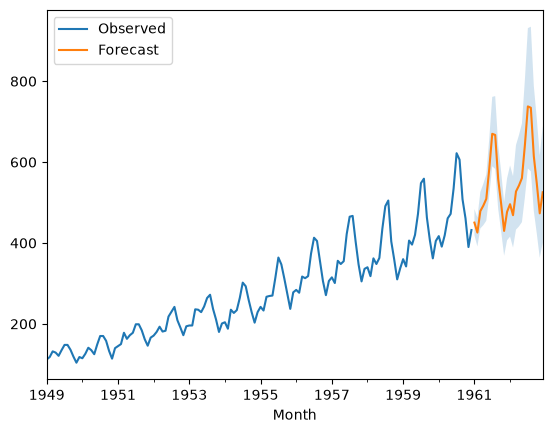

In [25]:
model = SARIMAX(log_s, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12))
fit = model.fit(disp=False)
print(fit.summary())

forecast = fit.get_forecast(steps=24)
pred = np.exp(forecast.predicted_mean)
ci = np.exp(forecast.conf_int())

fig, ax = plt.subplots()
s.plot(ax=ax, label="Observed")
pred.plot(ax=ax, label="Forecast")
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], alpha=0.2)
ax.legend()
plt.show()

In [36]:
# 1. Forecast over the test period length (1960)
steps = len(m_test)
forecast_log = sarima.get_forecast(steps=steps)

# 2. Exponentiate back to original passenger units
pred = np.exp(forecast_log.predicted_mean)
pred.index = m_test.index

# 3. Evaluate against m_test using your function
result_dict = m_eval(pred, "Optimal SARIMAX(0,1,1)x(0,1,1,12)")
m_results.append(result_dict)

# View final metrics
results_df = pd.DataFrame(m_results)
print(results_df)

                               model        MAE       RMSE
0          SARIMAX(0,1,1)x(0,1,1,12)  13.259348  18.592724
1  Optimal SARIMAX(0,1,1)x(0,1,1,12)  13.259348  18.592724
